# 11. Rebase del Oleaje (*Wave Overtopping* — EurOtop 2018)

Este cuaderno aplica el módulo `sedmor.overtopping` (implementado de forma independiente a partir del manual **EurOtop, 2018**) para evaluar:

1. Caudal medio y de diseño ($+1\sigma$) en **taludes lisos y diques de escollera** (`overtopping_slope`, `overtopping_rubble_mound`).
2. Cálculo inverso del **francobordo mínimo requerido** $R_c$ según límites tolerables (`solve_required_freeboard`).
3. Rebase en **muros verticales** en régimen pulsátil vs. impulsivo ($d^* < 0.23$, `overtopping_vertical_wall`).
4. Distribución de **volúmenes individuales** por ola mediante Weibull ($P_{ow}$, $V_{1\%}$, $V_{\max}$) y evaluación de seguridad (`individual_overtopping_volumes`, `classify_overtopping_hazard`).


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sedmor as sm

plt.rcParams["figure.dpi"] = 110


## 1. Caudal medio de rebase en talud liso vs. escollera (`overtopping_slope` y `overtopping_rubble_mound`)

Comparamos un paramento liso ($\gamma_f = 1.0$) frente a una coraza de escollera de doble capa sobre núcleo permeable ($\gamma_f = 0.40$) y frente a tetrápodos ($\gamma_f = 0.38$), bajo oleaje de tormenta $H_{m0} = 3.5\,\text{m}$, $T_{m-1,0} = 10.0\,\text{s}$ y talud $1\text{V}:2\text{H}$ ($\tan\alpha = 0.50$).


Para escollera 2 capas (diseño): Rc(q <= 10 L/s/m) = 3.77 m | Rc(q <= 0.1 L/s/m) = 6.08 m


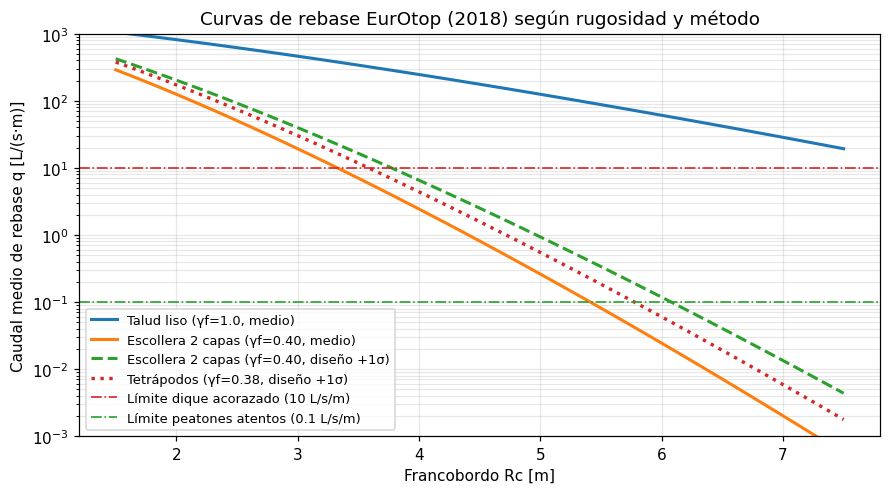

In [2]:
Hm0 = 3.5
Tm_10 = 10.0
slope = 0.50
Rc_grid = np.linspace(1.5, 7.5, 120)

liso_mean = sm.overtopping.overtopping_slope(Hm0, Tm_10, slope, Rc_grid, gamma_f=1.0, method="mean")
roca_mean = sm.overtopping.overtopping_rubble_mound(Hm0, Tm_10, slope, Rc_grid, gamma_f=0.40, method="mean")
roca_des = sm.overtopping.overtopping_rubble_mound(Hm0, Tm_10, slope, Rc_grid, gamma_f=0.40, method="design")
tetra_des = sm.overtopping.overtopping_rubble_mound(
    Hm0, Tm_10, slope, Rc_grid,
    gamma_f=sm.overtopping.EUROTOP_ROUGHNESS_FACTORS["tetrapods"],
    method="design",
)

rc_paseo = sm.overtopping.solve_required_freeboard(
    0.1, Hm0=Hm0, Tm_10=Tm_10, slope=slope, gamma_f=0.40, method="design", unit="l_s_m"
)
rc_dique = sm.overtopping.solve_required_freeboard(
    10.0, Hm0=Hm0, Tm_10=Tm_10, slope=slope, gamma_f=0.40, method="design", unit="l_s_m"
)

print(f"Para escollera 2 capas (diseño): Rc(q <= 10 L/s/m) = {rc_dique:.2f} m | Rc(q <= 0.1 L/s/m) = {rc_paseo:.2f} m")

fig, ax = plt.subplots(figsize=(8.2, 4.6))
ax.semilogy(Rc_grid, liso_mean.q_l_s_m, label="Talud liso (γf=1.0, medio)", lw=2.0)
ax.semilogy(Rc_grid, roca_mean.q_l_s_m, label="Escollera 2 capas (γf=0.40, medio)", lw=2.0)
ax.semilogy(Rc_grid, roca_des.q_l_s_m, "--", label="Escollera 2 capas (γf=0.40, diseño +1σ)", lw=2.0)
ax.semilogy(Rc_grid, tetra_des.q_l_s_m, ":", label="Tetrápodos (γf=0.38, diseño +1σ)", lw=2.2)

ax.axhline(10.0, color="tab:red", ls="-.", lw=1.1, label="Límite dique acorazado (10 L/s/m)")
ax.axhline(0.1, color="tab:green", ls="-.", lw=1.1, label="Límite peatones atentos (0.1 L/s/m)")
ax.set_ylim(1e-3, 1e3)
ax.set_xlabel("Francobordo Rc [m]")
ax.set_ylabel("Caudal medio de rebase q [L/(s·m)]")
ax.set_title("Curvas de rebase EurOtop (2018) según rugosidad y método")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8.5)
plt.tight_layout()
plt.show()


## 2. Muros verticales: transición no impulsivo / impulsivo y volúmenes individuales

Evaluamos el efecto de la profundidad al pie $h_{\text{toe}}$ sobre un muro vertical con francobordo fijo $R_c = 3.2\,\text{m}$ bajo $H_{m0} = 2.6\,\text{m}$ y $T_{m-1,0} = 10.0\,\text{s}$, y posteriormente estimamos la distribución Weibull de volúmenes individuales de rebase en una tormenta de 3 horas.


Transición d* = 0.23 ocurre cerca de h_toe ≈ 9.70 m
Escollera Rc=4.0 m: q=6.54 L/(s·m) | Pow=6.6% | N_ow=86 olas | V_mean=816 L/m | V_max=5120 L/m | Aceptable=False


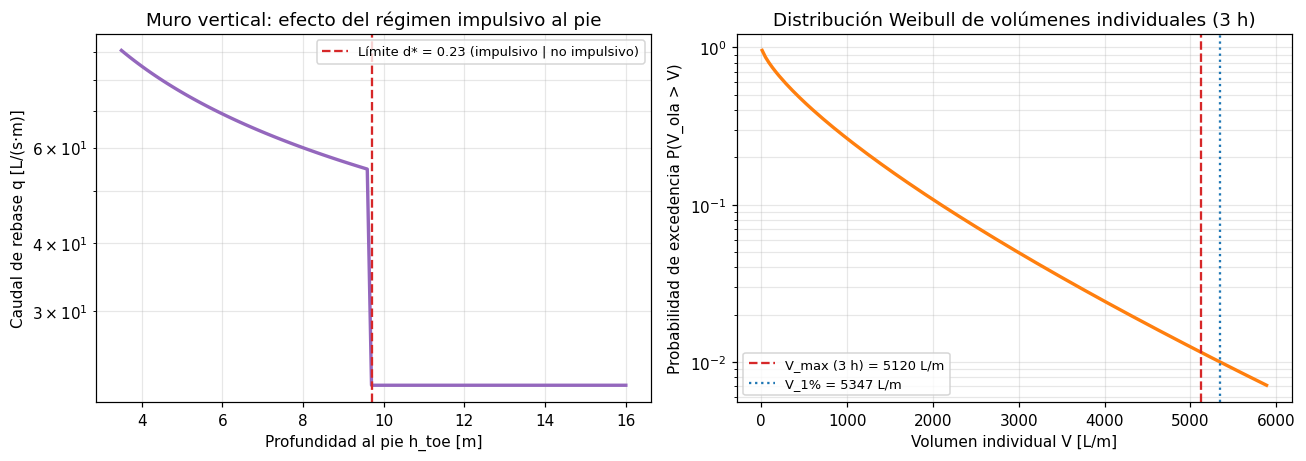

In [3]:
h_toes = np.linspace(3.5, 16.0, 120)
vw = sm.overtopping.overtopping_vertical_wall(Hm0=2.6, Tm_10=10.0, h_toe=h_toes, Rc=3.2, method="design")

idx_trans = np.argmax(~vw.is_impulsive)
print(f"Transición d* = 0.23 ocurre cerca de h_toe ≈ {h_toes[idx_trans]:.2f} m")

# Distribución Weibull de volúmenes individuales para el dique de escollera con Rc = 4.0 m
Rc_eval = 4.0
q_esc = sm.overtopping.overtopping_rubble_mound(3.5, 10.0, 0.50, Rc_eval, gamma_f=0.40, method="design")
ru_esc = sm.runup.runup_eurotop(3.5, 10.0, 0.50, gamma_f=0.40, method="design")
vols = sm.overtopping.individual_overtopping_volumes(
    q=q_esc.q_m3_s_m, Tm=8.2, Ru2_percent=ru_esc.R2_percent, Rc=Rc_eval,
    storm_duration_s=3.0 * 3600.0, Hm0=3.5, Tm_10=10.0
)
haz = sm.overtopping.classify_overtopping_hazard(
    q_esc.q_l_s_m, V_max_l_m=1000.0 * vols.V_max, category="breakwater_rear_armoured"
)

print(
    f"Escollera Rc={Rc_eval:.1f} m: q={q_esc.q_l_s_m:.2f} L/(s·m) | "
    f"Pow={100*vols.P_ow:.1f}% | N_ow={vols.N_overtopping:.0f} olas | "
    f"V_mean={1000*vols.V_mean:.0f} L/m | V_max={1000*vols.V_max:.0f} L/m | "
    f"Aceptable={haz.is_acceptable}"
)

v_grid = np.linspace(0.01, max(vols.V_max * 1.15, 0.5), 150)
p_exc = np.exp(-np.power(v_grid / vols.weibull_a, vols.weibull_b))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))
ax1.semilogy(h_toes, vw.q_l_s_m, lw=2.2, color="tab:purple")
ax1.axvline(h_toes[idx_trans], color="tab:red", ls="--", label="Límite d* = 0.23 (impulsivo | no impulsivo)")
ax1.set_xlabel("Profundidad al pie h_toe [m]")
ax1.set_ylabel("Caudal de rebase q [L/(s·m)]")
ax1.set_title("Muro vertical: efecto del régimen impulsivo al pie")
ax1.grid(True, which="both", alpha=0.3)
ax1.legend(fontsize=8.5)

ax2.semilogy(v_grid * 1000.0, p_exc, lw=2.2, color="tab:orange")
ax2.axvline(vols.V_max * 1000.0, color="tab:red", ls="--", label=f"V_max (3 h) = {1000*vols.V_max:.0f} L/m")
ax2.axvline(vols.V_1percent * 1000.0, color="tab:blue", ls=":", label=f"V_1% = {1000*vols.V_1percent:.0f} L/m")
ax2.set_xlabel("Volumen individual V [L/m]")
ax2.set_ylabel("Probabilidad de excedencia P(V_ola > V)")
ax2.set_title("Distribución Weibull de volúmenes individuales (3 h)")
ax2.grid(True, which="both", alpha=0.3)
ax2.legend(fontsize=8.5)

plt.tight_layout()
plt.show()
